This file calculated the DOA using Woodworths equation for all recordings at all heights, to show the difference in the calculated ITD by height and angle

In [47]:
import soundfile as sf
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path    
from scipy.fft import fft, ifft
from scipy.optimize import brentq

from HATS_functions import fft_cross_correlation, woodworth_itd, itd_to_angle

angles = ["-90", "-67.5", "-45", "-22.5", "0", "22.5", "45", "67.5", "90"]
heights = ["H1", "H2", "H3"]  
PathToFiles = "../Audio_Files/HATS/"

In [ ]:
recordings = {}

for height in heights:
    recordings[height] = {}
    for angle in angles:
        folder = Path(PathToFiles) / str(height) / str(angle)
        
        if folder.is_dir():
            recordings[height][angle] = {
                'L': folder / "L.wav",
                'R': folder / "R.wav"
            }
        else:
            print(f"Missing folder: {folder}")
    
print(recordings)

{'H1': {'-90': {'L': PosixPath('../Audio_Files/HATS/H1/-90/L.wav'), 'R': PosixPath('../Audio_Files/HATS/H1/-90/R.wav')}, '-67.5': {'L': PosixPath('../Audio_Files/HATS/H1/-67.5/L.wav'), 'R': PosixPath('../Audio_Files/HATS/H1/-67.5/R.wav')}, '-45': {'L': PosixPath('../Audio_Files/HATS/H1/-45/L.wav'), 'R': PosixPath('../Audio_Files/HATS/H1/-45/R.wav')}, '-22.5': {'L': PosixPath('../Audio_Files/HATS/H1/-22.5/L.wav'), 'R': PosixPath('../Audio_Files/HATS/H1/-22.5/R.wav')}, '0': {'L': PosixPath('../Audio_Files/HATS/H1/0/L.wav'), 'R': PosixPath('../Audio_Files/HATS/H1/0/R.wav')}, '22.5': {'L': PosixPath('../Audio_Files/HATS/H1/22.5/L.wav'), 'R': PosixPath('../Audio_Files/HATS/H1/22.5/R.wav')}, '45': {'L': PosixPath('../Audio_Files/HATS/H1/45/L.wav'), 'R': PosixPath('../Audio_Files/HATS/H1/45/R.wav')}, '67.5': {'L': PosixPath('../Audio_Files/HATS/H1/67.5/L.wav'), 'R': PosixPath('../Audio_Files/HATS/H1/67.5/R.wav')}, '90': {'L': PosixPath('../Audio_Files/HATS/H1/90/L.wav'), 'R': PosixPath('../Au

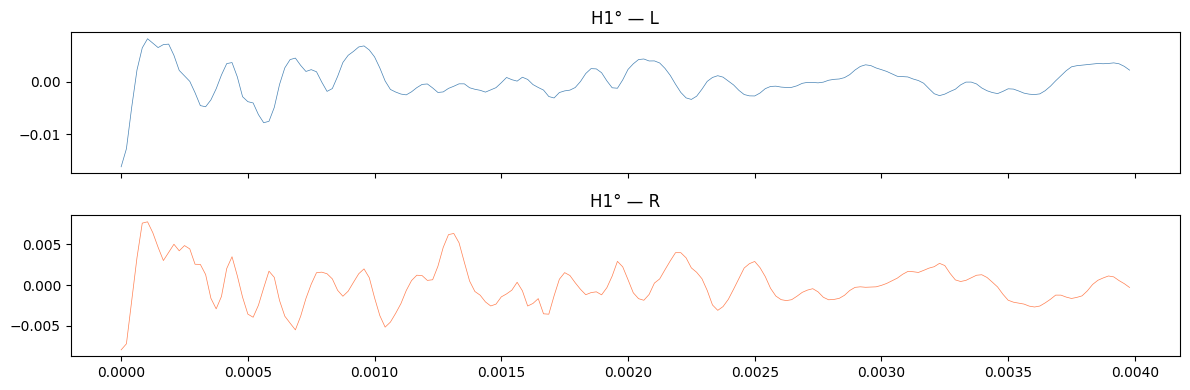

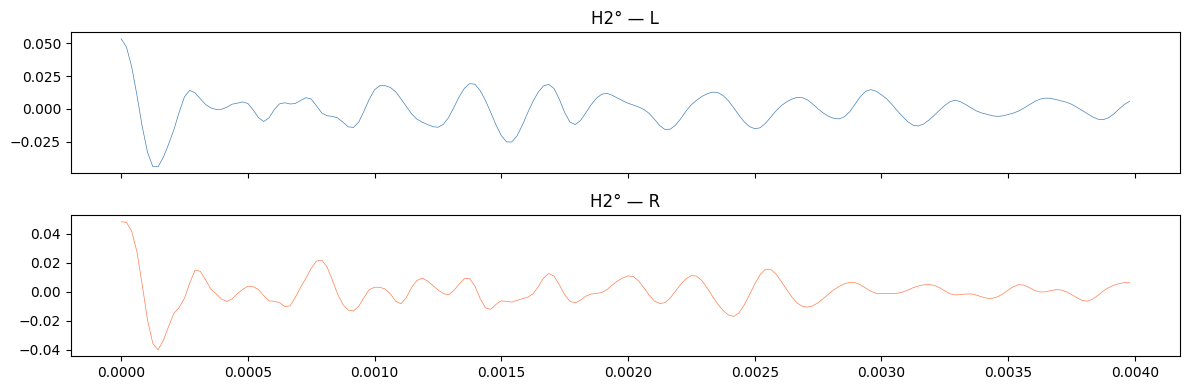

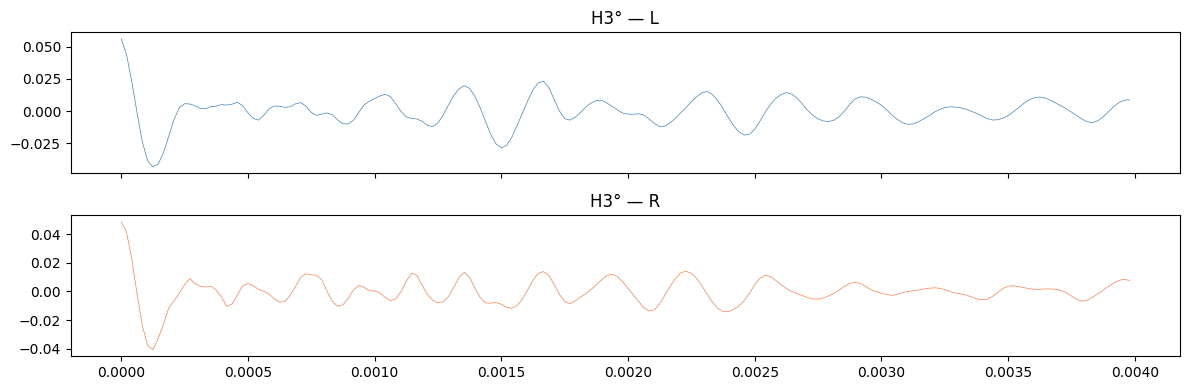

In [49]:
for name, files in recordings.items():
    for angle, files2 in files.items():
    
        dataL, fs = sf.read(files2['L']) 
        dataR, fs = sf.read(files2['R'])
    
        L_click_idx = np.argmax(np.abs(dataL))
        R_click_idx = np.argmax(np.abs(dataR))
    
        L_Trimmed = dataL[L_click_idx:]
        R_Trimmed = dataR[R_click_idx:]
    
        samples = int(fs/250)
        t = np.arange(samples)/fs
    
        fig, (axL, axR) = plt.subplots(2, 1, figsize=(12, 4), sharex=True)
        axL.plot(t, L_Trimmed[:samples], linewidth=0.5, color='steelblue')
        axR.plot(t, R_Trimmed[:samples], linewidth=0.5, color='coral')
        axL.set_title(f'{name}° — L')
        axR.set_title(f'{name}° — R')
        plt.tight_layout()
        plt.show()
        break 

In [50]:
d = 0.21
c = 343
r = 0.0875 

results = {}

for height, angle_dict in recordings.items():
    results[height] = {}
    for angle, files in angle_dict.items():
        dataL, fs = sf.read(files['L'])
        dataR, fs = sf.read(files['R'])
    
        L_click_idx = np.argmax(np.abs(dataL))
        R_click_idx = np.argmax(np.abs(dataR))
    
        click_offset = R_click_idx - L_click_idx 

        L_Trimmed = dataL[L_click_idx + int(fs*2):]
        R_Trimmed = dataR[R_click_idx + int(fs*2):]

        min_len = min(len(L_Trimmed), len(R_Trimmed))
        L_Trimmed = L_Trimmed[:min_len]
        R_Trimmed = R_Trimmed[:min_len]


        correlation = fft_cross_correlation(L_Trimmed, R_Trimmed)
        
        n = len(L_Trimmed)
        lags = np.arange(-n//2, n//2)
        lags = lags[:len(correlation)]

        max_itd_samples = int((d / c) * (np.pi/2 + 1) * fs)
        mask = (lags >= -max_itd_samples) & (lags <= max_itd_samples)
        itd_samples = lags[mask][np.argmax(correlation[mask])]
        itd_seconds = itd_samples / fs
        
        angle_deg = itd_to_angle(itd_seconds, r, fs)

        itd_expected = woodworth_itd(float(angle), r)
        
        results[height][angle] = {'expected': angle, 'calculated': angle_deg}   
        
print(results)        

{'H1': {'-90': {'expected': '-90', 'calculated': np.float64(-90.0)}, '-67.5': {'expected': '-67.5', 'calculated': np.float64(-75.53645823228553)}, '-45': {'expected': '-45', 'calculated': np.float64(-38.89260654344047)}, '-22.5': {'expected': '-22.5', 'calculated': np.float64(-16.490405930801895)}, '0': {'expected': '0', 'calculated': np.float64(-4.681759415639726)}, '22.5': {'expected': '22.5', 'calculated': np.float64(90.0)}, '45': {'expected': '45', 'calculated': np.float64(61.80323225010033)}, '67.5': {'expected': '67.5', 'calculated': np.float64(90.0)}, '90': {'expected': '90', 'calculated': np.float64(90.0)}}, 'H2': {'-90': {'expected': '-90', 'calculated': np.float64(-90.0)}, '-67.5': {'expected': '-67.5', 'calculated': np.float64(-58.67610562553954)}, '-45': {'expected': '-45', 'calculated': np.float64(-36.28198988155194)}, '-22.5': {'expected': '-22.5', 'calculated': np.float64(-7.02753650598425)}, '0': {'expected': '0', 'calculated': np.float64(11.73886533001672)}, '22.5': {'

H1: expected=[-90.0, -67.5, -45.0, -22.5, 0.0, 22.5, 45.0, 67.5, 90.0]
H1: calculated=[np.float64(-90.0), np.float64(-75.53645823228553), np.float64(-38.89260654344047), np.float64(-16.490405930801895), np.float64(-4.681759415639726), np.float64(90.0), np.float64(61.80323225010033), np.float64(90.0), np.float64(90.0)]
H2: expected=[-90.0, -67.5, -45.0, -22.5, 0.0, 22.5, 45.0, 67.5, 90.0]
H2: calculated=[np.float64(-90.0), np.float64(-58.67610562553954), np.float64(-36.28198988155194), np.float64(-7.02753650598425), np.float64(11.73886533001672), np.float64(33.70978794239421), np.float64(61.80323225010033), np.float64(90.0), np.float64(90.0)]
H3: expected=[-90.0, -67.5, -45.0, -22.5, 0.0, 22.5, 45.0, 67.5, 90.0]
H3: calculated=[np.float64(-90.0), np.float64(-79.38096251876942), np.float64(-38.89260654344047), np.float64(-23.732179840041045), np.float64(16.490405930801895), np.float64(68.38959951798483), np.float64(26.186447448454544), np.float64(68.38959951798483), np.float64(90.0)]


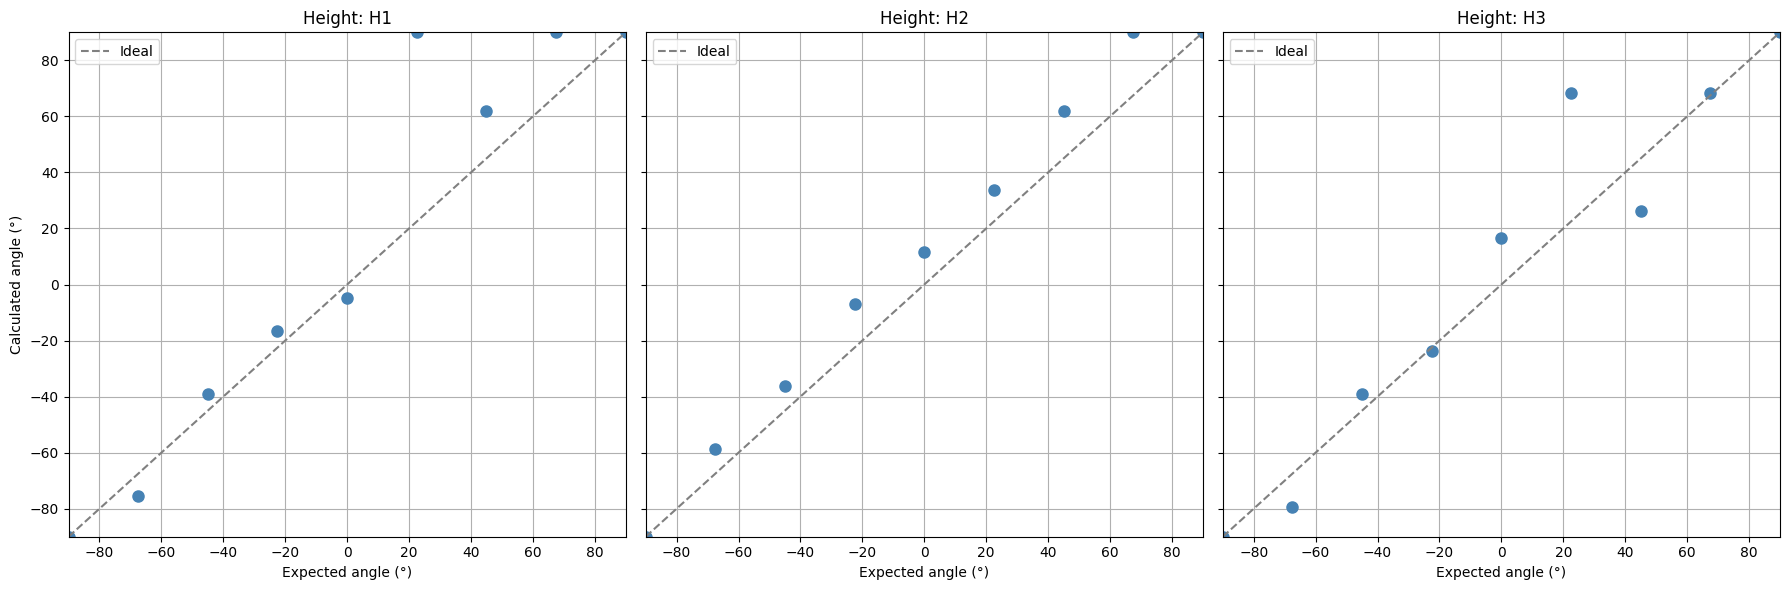

In [51]:
n_heights = 3
fig, axes = plt.subplots(1, n_heights, figsize=(6*n_heights, 6), sharex=True, sharey=True)

if n_heights == 1:
    axes = [axes]
    
heights_list = ['H1', 'H2', 'H3']

for ax, height in zip(axes, heights_list):
    angle_data = results[height]
    
    sorted_angles = sorted(angle_data.keys(), key=lambda x: float(x))
    expected = [float(a) for a in sorted_angles]
    calculated = [angle_data[a]['calculated'] for a in sorted_angles]
    
    print(f"{height}: expected={expected}")
    print(f"{height}: calculated={calculated}")
    
    ax.plot(expected, calculated, 'o', color='steelblue', markersize=8)
    ax.plot([-90, 90], [-90, 90], '--', color='gray', label='Ideal')
    
    ax.set_xlabel('Expected angle (°)')
    ax.set_title(f'Height: {height}')
    ax.set_xlim(-90, 90)
    ax.set_ylim(-90, 90)
    ax.grid(True)
    ax.legend()

axes[0].set_ylabel('Calculated angle (°)')
plt.tight_layout()
plt.show()

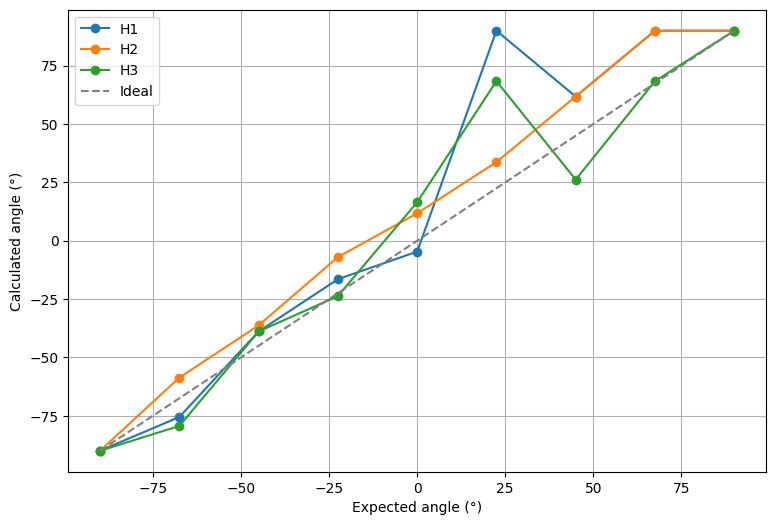

In [52]:
fig, ax = plt.subplots(figsize=(9, 6))
for height in heights_list:
    sorted_angles = sorted(results[height].keys(), key=lambda x: float(x))
    expected = [float(a) for a in sorted_angles]
    calculated = [results[height][a]['calculated'] for a in sorted_angles]
    ax.plot(expected, calculated, 'o-', label=height)
ax.plot([-90,90],[-90,90],'--', color='gray', label='Ideal')
ax.set_xlabel('Expected angle (°)'); ax.set_ylabel('Calculated angle (°)')
ax.legend(); ax.grid(True)
plt.show()

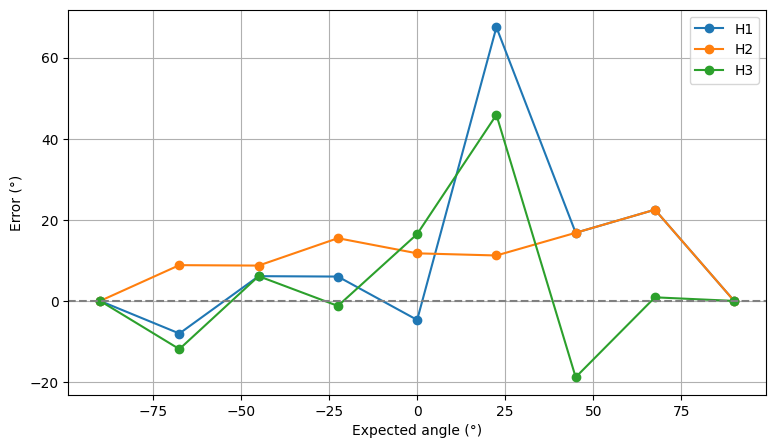

In [53]:
fig, ax = plt.subplots(figsize=(9, 5))
for height in heights_list:
    sorted_angles = sorted(results[height].keys(), key=lambda x: float(x))
    expected = [float(a) for a in sorted_angles]
    error = [results[height][a]['calculated'] - float(a) for a in sorted_angles]
    ax.plot(expected, error, 'o-', label=height)
ax.axhline(0, color='gray', linestyle='--')
ax.set_xlabel('Expected angle (°)'); ax.set_ylabel('Error (°)')
ax.legend(); ax.grid(True)
plt.show()

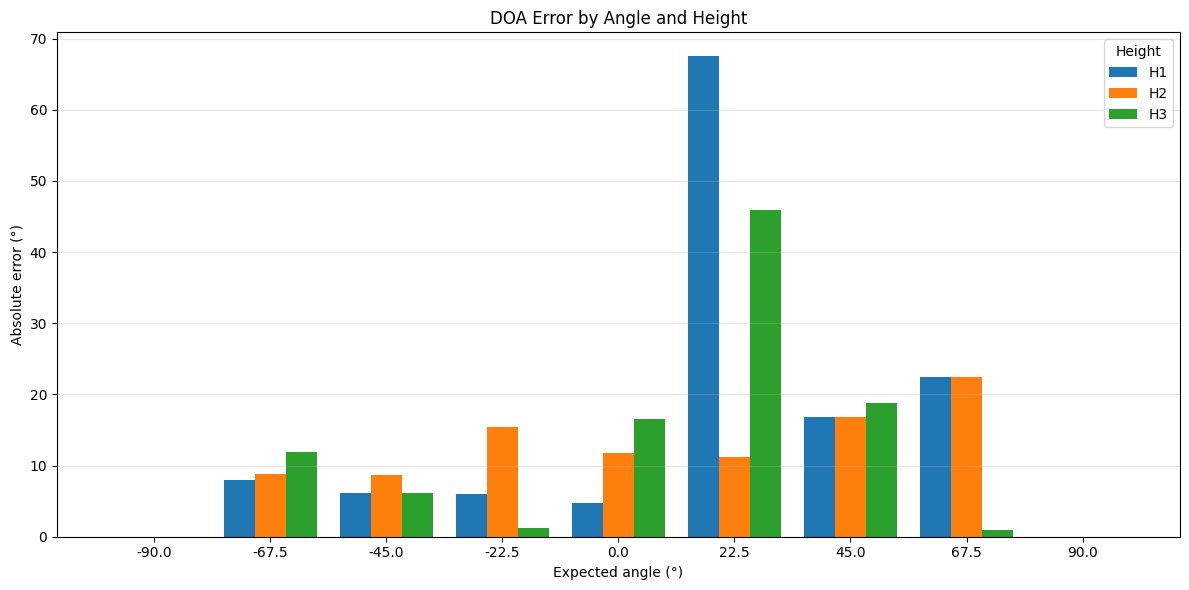

In [54]:
import numpy as np

heights_list = list(results.keys())
angles_list = sorted([float(a) for a in results[heights_list[0]].keys()])

fig, ax = plt.subplots(figsize=(12, 6))

x = np.arange(len(angles_list))
width = 0.8 / len(heights_list)

for i, height in enumerate(heights_list):
    errors = []
    for angle in angles_list:
        key = str(angle) if str(angle) in results[height] else str(int(angle))
        error = abs(results[height][key]['calculated'] - angle)
        errors.append(error)
    
    ax.bar(x + i*width, errors, width, label=height)

ax.set_xlabel('Expected angle (°)')
ax.set_ylabel('Absolute error (°)')
ax.set_title('DOA Error by Angle and Height')
ax.set_xticks(x + width * (len(heights_list)-1) / 2)
ax.set_xticklabels(angles_list)
ax.legend(title='Height')
ax.grid(True, axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

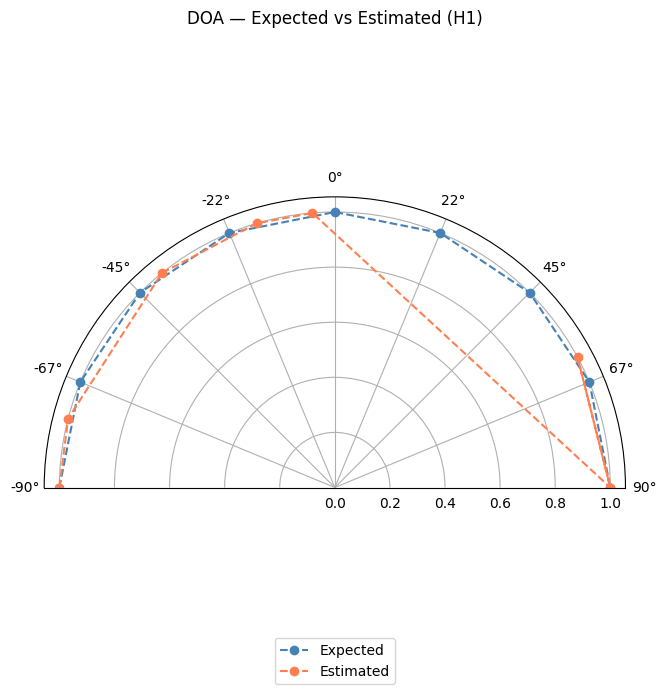

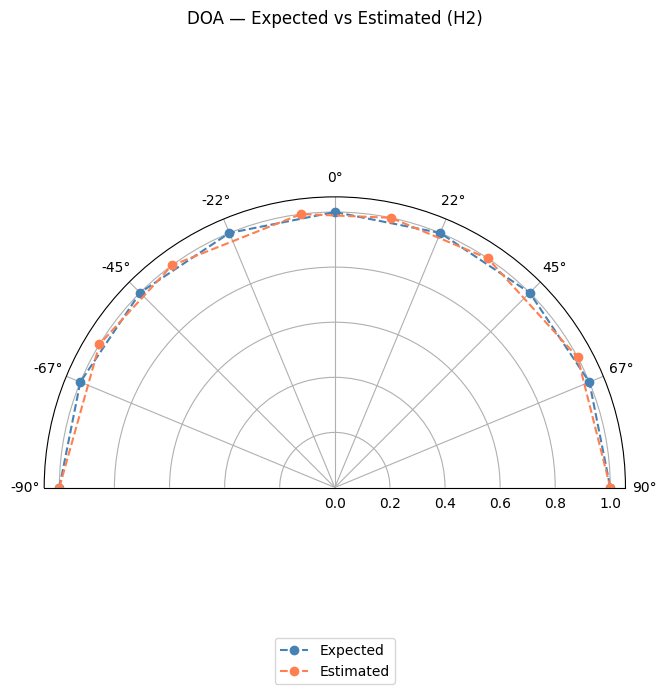

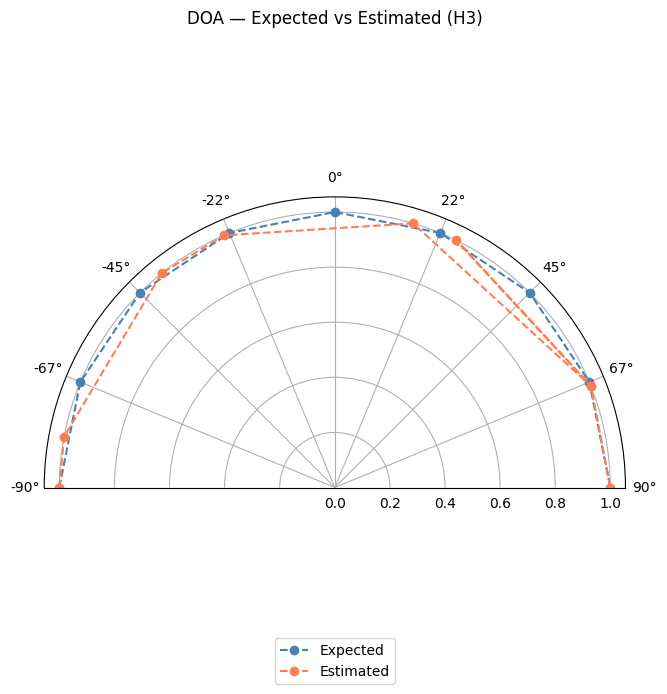

In [55]:
from pathlib import Path

figures_dir = Path("figures")
figures_dir.mkdir(exist_ok=True)


def plot_and_save(results_for_height, height_label, save_path):
    # Sort by expected angle (numeric)
    items = sorted(results_for_height.items(), key=lambda kv: float(kv[0]))
    expected = [float(v['expected']) for _, v in items]
    measured = [float(v['calculated']) for _, v in items]

    fig, ax = plt.subplots(subplot_kw={'projection': 'polar'}, figsize=(7, 7))

    expected_rad = -np.radians(expected) + np.pi/2
    measured_rad = -np.radians(measured) + np.pi/2

    ax.plot(expected_rad, np.ones(len(expected_rad)), 'o--',
            color='steelblue', label='Expected')
    ax.plot(measured_rad, np.ones(len(measured_rad)), 'o--',
            color='coral', label='Estimated')

    ax.set_thetamin(0)
    ax.set_thetamax(180)
    ax.set_thetagrids(np.arange(0, 181, 22.5),
                      labels=[f'{int(a)}°' for a in np.arange(90, -91, -22.5)])

    ax.set_title(f'DOA — Expected vs Estimated ({height_label})', pad=20)
    ax.legend(loc='lower center', bbox_to_anchor=(0.5, -0.1))
    plt.tight_layout()

    fig.savefig(f"{save_path}.png", dpi=200, bbox_inches='tight')
    fig.savefig(f"{save_path}.pdf", bbox_inches='tight')
    plt.show()
    plt.close(fig)


# Save one polar plot per height
for height, results_for_height in results.items():
    plot_and_save(results_for_height, height, figures_dir / f"doa_polar_{height}")

In [56]:
import csv

with open(figures_dir / "doa_results.csv", 'w', newline='') as f:
    writer = csv.writer(f)
    writer.writerow(['height', 'expected_angle', 'calculated_angle', 'error'])
    for height, results_for_height in results.items():
        for angle_key, data in results_for_height.items():
            exp = float(data['expected'])
            meas = float(data['calculated'])
            writer.writerow([height, exp, meas, meas - exp])